# Exploring specificity prediction normalisation

In this notebook, we explore whether our developped model can normalise the effects that come from more confident structure prediction.

In [1]:
import glob
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.models import PAEAggregator

In [2]:
sequences_1500 = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences_1500.index = sequences_1500.index.astype(str)

confidence_scores_1500 = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores_1500['name'] = confidence_scores_1500['name'].astype(str)

confidence_scores_1500 = confidence_scores_1500.merge(sequences_1500, how='left', left_on='name', right_index=True)

confidence_scores_1500['source'] = 'Sequences'

In [3]:
fold_map = sequences_1500.groupby(['peptide', 'mhc1']).apply(
    lambda group: group['fold'].unique()[0], include_groups=False
)
fold_map.name = 'fold'
fold_map = fold_map.to_frame().reset_index()

In [4]:
sequences_af_training = pd.read_csv('../data/interim/af_training_structures.csv')
sequences_af_training = sequences_af_training.merge(fold_map, how='left', on=['peptide', 'mhc1'])
sequences_af_training = sequences_af_training.set_index('id')

confidence_scores_af_training = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_af_training.csv')
confidence_scores_af_training = confidence_scores_af_training.merge(
    sequences_af_training, how='left', left_on='name', right_index=True
)

confidence_scores_af_training['source'] = 'AF-Training'

In [5]:
confidence_scores = pd.concat([confidence_scores_1500, confidence_scores_af_training]).reset_index(drop=True)

In [6]:
min_size = confidence_scores.value_counts(['source', 'label']).min()
confidence_scores_down_sample = confidence_scores.groupby(['source', 'label']).sample(min_size, random_state=123)

In [7]:
def plot_separation(data: pd.DataFrame, x: str, *, invert_roc_auc: bool = False) -> tuple[Figure, Axes]:
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    for i, (data_subset, title, separator, invert_score) in enumerate(
        zip(
            (data[data['source'] == 'Sequences'], data[data['source'] == 'AF-Training'], data, data),
            ('Sequences', 'AF training structures', 'Overall', 'Using data source'),
            ('label', 'label', 'label', 'source'),
            (True, True, True, False),
            strict=True,
        )
    ):
        axes[i % 2, i // 2].set_title(title)
        sns.histplot(
            data_subset,
            x=x,
            hue=separator,
            stat='probability',
            ax=axes[i % 2, i // 2],
        )

        score = roc_auc_score(data_subset[separator], data_subset[x])
        if invert_score ^ invert_roc_auc:
            score = 1 - score

        axes[i % 2, i // 2].text(
            0.50,
            0.95,
            f'ROC-AUC: {score: .2f}',
            transform=axes[i % 2, i // 2].transAxes,
            fontsize=12,
            horizontalalignment='center',
            verticalalignment='top',
        )

    return fig, axes

## Original

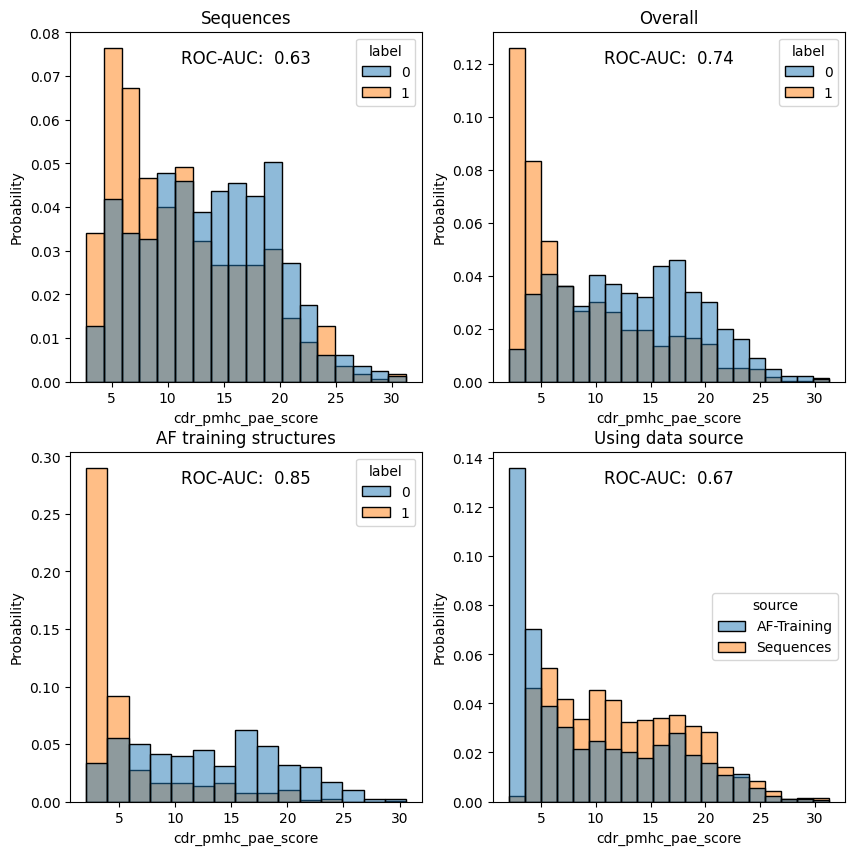

In [8]:
plot_separation(confidence_scores_down_sample, x='cdr_pmhc_pae_score')
plt.show()

Here, we see an effect that the distribution that the pairing comes from can have a larger effect than the label of that pairing.

## Model

In [9]:
paes = {}
for path in glob.glob('../data/interim/pae_padded_af3_af3_tcrmodel2/*_pae.txt'):
    info = re.match(
        r'^(?P<name>[A-Za-z0-9_]+)_(?P<seed>\d+)_(?P<sample>\d+)_pae.txt', os.path.basename(path)
    ).groupdict()
    pae = np.loadtxt(path)

    paes[(info['name'], int(info['seed']), int(info['sample']))] = pae

In [10]:
max_val = 0

for (name, _, _), pae in paes.items():
    if name not in sequences_1500.index:
        continue

    if (pae_max := np.nanmax(pae)) > max_val:
        max_val = pae_max

paes_scaled = {key: np.nan_to_num((max_val - pae) / max_val) for key, pae in paes.items()}

### Untrained

In [11]:
model = PAEAggregator(3120)
model.eval()


def predict_untrained(name: str, seed: int, sample: int) -> float:
    pae = torch.Tensor(paes_scaled[(name, seed, sample)].flatten())
    untrained_prediction = model(pae).cpu().detach().numpy()

    return float(untrained_prediction)


confidence_scores_down_sample['untrained_prediction'] = confidence_scores_down_sample[['name', 'seed', 'sample']].apply(
    lambda row: predict_untrained(row['name'], row['seed'], row['sample']), axis=1
)

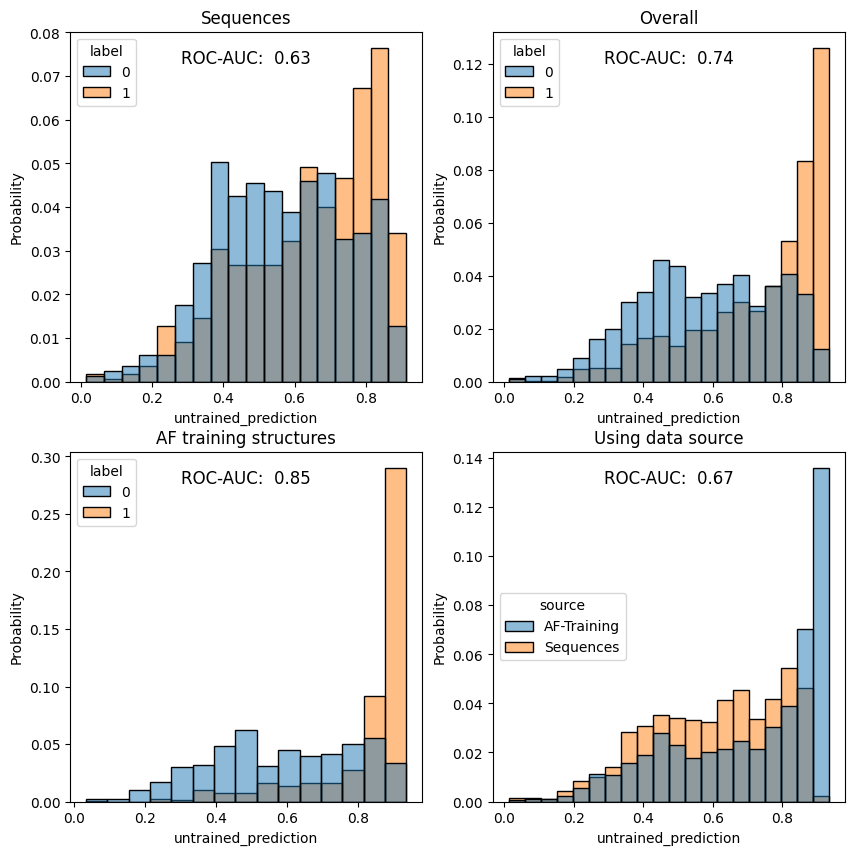

In [12]:
plot_separation(confidence_scores_down_sample, x='untrained_prediction', invert_roc_auc=True)
plt.show()

### Trained

In [13]:
def predict_trained_fold(model: torch.nn.Module, name: str, seed: int, sample: int) -> float:
    pae = torch.Tensor(paes_scaled[(name, seed, sample)].flatten())
    trained_prediction = model(pae).cpu().detach().numpy()

    return float(trained_prediction)


confidence_scores_down_sample['trained_prediction'] = np.nan

folds = sorted(str(int(fold)) for fold in confidence_scores_down_sample['fold'].unique() if not np.isnan(fold))

models = {}
for fold in folds:
    model = PAEAggregator(3120)
    model.load_state_dict(
        torch.load(
            f'../models/PAEAggregator_af3_af3_tcrmodel2/model_{int(fold)}.pt',
            weights_only=True,
            map_location=torch.device('cpu'),
        ),
    )
    model.eval()
    models[fold] = model

for fold in (fold for fold in confidence_scores_down_sample['fold'].unique() if not np.isnan(fold)):
    confidence_scores_down_sample.loc[confidence_scores_down_sample['fold'] == fold, 'trained_prediction'] = (
        confidence_scores_down_sample.loc[
            confidence_scores_down_sample['fold'] == fold, ['name', 'seed', 'sample']
        ].apply(
            lambda row, model=models[str(int(fold))]: predict_trained_fold(
                model, row['name'], row['seed'], row['sample']
            ),
            axis=1,
        )
    )

In [14]:
def predict_ensemble(models: dict[str, torch.nn.Module], name: str, seed: int, sample: int) -> float:
    pae = torch.Tensor(paes_scaled[(name, seed, sample)].flatten())

    trained_predictions = np.array([model(pae).cpu().detach().numpy() for model in models.values()])

    return np.mean(trained_predictions)


confidence_scores_down_sample.loc[confidence_scores_down_sample['trained_prediction'].isna(), 'trained_prediction'] = (
    confidence_scores_down_sample.loc[
        confidence_scores_down_sample['trained_prediction'].isna(), ['name', 'seed', 'sample']
    ].apply(
        lambda row, models=models: predict_ensemble(models, row['name'], row['seed'], row['sample']),
        axis=1,
    )
)

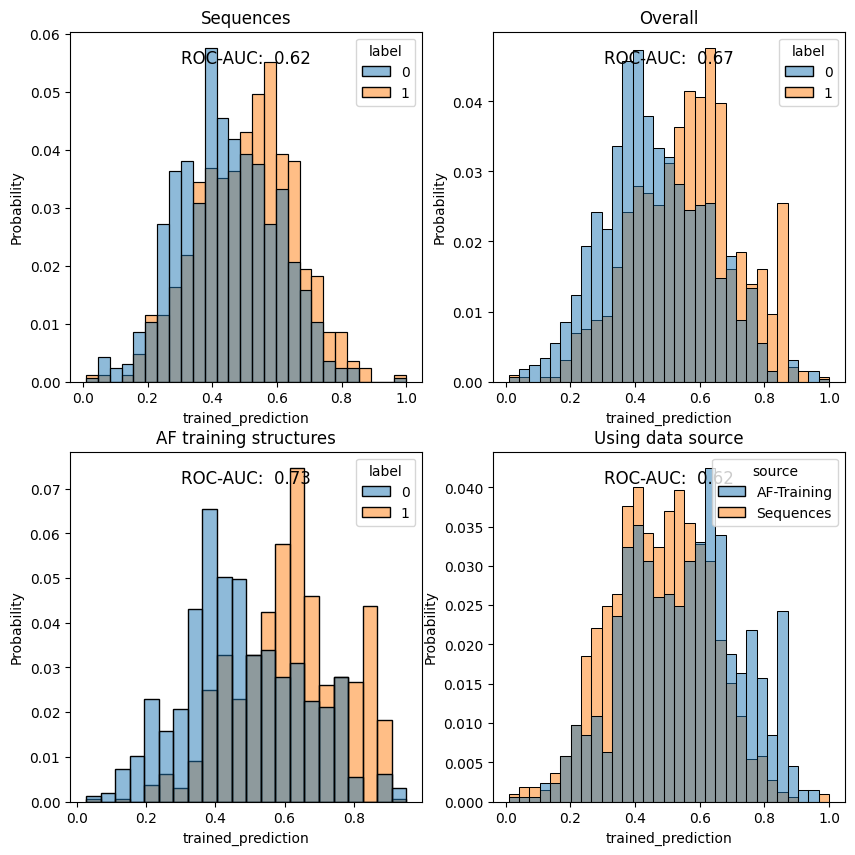

In [15]:
plot_separation(confidence_scores_down_sample, x='trained_prediction', invert_roc_auc=True)
plt.show()